In [2]:
pip install notebook pandas matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import matplotlib.pyplot as plt


In [6]:

data = {
    "Company": ["Microsoft", "Microsoft", "Microsoft",
                "Apple", "Apple", "Apple",
                "Tesla", "Tesla", "Tesla"],
    "Year": [2021, 2022, 2023,
             2021, 2022, 2023,
             2021, 2022, 2023],
   
    "Total Revenue": [168.09, 198.27, 211.92,
                      394328, 383285, 391035,
                      365817, 383285, 383285],
    
    "Net Income": [61271, 72738, 72842,
                   3365817, 394328, 93736,
                   5519, 12556, 15467],
    
    "Total Assets": [333779, 364840, 411942,
                     352755, 352583, 364980,
                     52150, 82338, 106838],
    
    "Total Liabilities": [205750, 198298, 212301,
                          153982, 290437, 308030,
                          287912, 302083, 43980],
    
    "Cash Flow from Ops": [76740, 89035, 87887,
                           104038, 122151, 110543,
                           18144, 16924, 13726]
}

df = pd.DataFrame(data)
df


,Company,Year,Total Revenue,Net Income,Total Assets,Total Liabilities,Cash Flow from Ops
0,Microsoft,2021,168.09,61271,333779,205750,76740
1,Microsoft,2022,198.27,72738,364840,198298,89035
2,Microsoft,2023,211.92,72842,411942,212301,87887
3,Apple,2021,394328.00,3365817,352755,153982,104038
4,Apple,2022,383285.00,394328,352583,290437,122151
5,Apple,2023,391035.00,93736,364980,308030,110543
6,Tesla,2021,365817.00,5519,52150,287912,18144
7,Tesla,2022,383285.00,12556,82338,302083,16924
8,Tesla,2023,383285.00,15467,106838,43980,13726


In [7]:
df.to_csv("financial_report.csv", index=False)



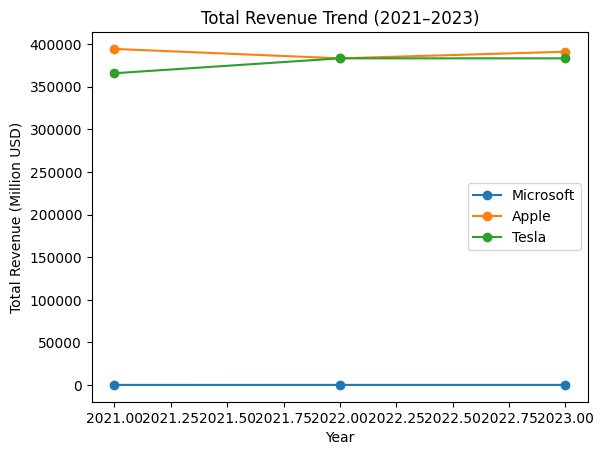

In [8]:
import matplotlib.pyplot as plt

for company in df["Company"].unique():
    subset = df[df["Company"] == company]
    plt.plot(subset["Year"], subset["Total Revenue"], marker="o", label=company)

plt.xlabel("Year")
plt.ylabel("Total Revenue (Million USD)")
plt.title("Total Revenue Trend (2021–2023)")
plt.legend()
plt.show()


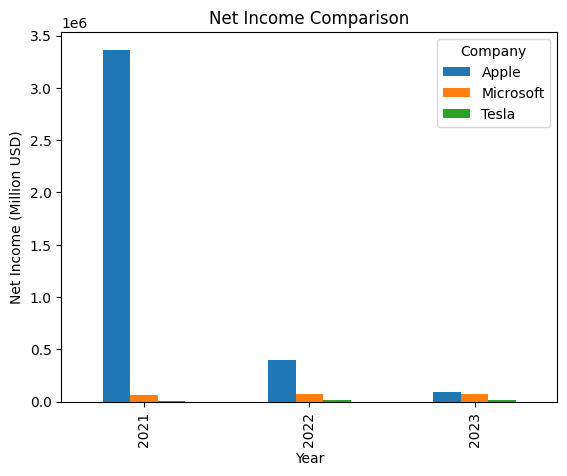

In [9]:
df.pivot(index="Year", columns="Company", values="Net Income").plot(kind="bar")
plt.ylabel("Net Income (Million USD)")
plt.title("Net Income Comparison")
plt.show()


In [10]:
# Revenue Growth %
df['Revenue Growth (%)'] = df.groupby(['Company'])['Total Revenue'].pct_change() * 100

# Net Income Growth %
df['Net Income Growth (%)'] = df.groupby(['Company'])['Net Income'].pct_change() * 100

# Assets Growth %
df['Assets Growth (%)'] = df.groupby(['Company'])['Total Assets'].pct_change() * 100

# Liabilities Growth %
df['Liabilities Growth (%)'] = df.groupby(['Company'])['Total Liabilities'].pct_change() * 100

# Cash Flow Growth %
df['Cash Flow Growth (%)'] = df.groupby(['Company'])['Cash Flow from Ops'].pct_change() * 100

df



,Company,Year,Total Revenue,Net Income,Total Assets,Total Liabilities,Cash Flow from Ops,Revenue Growth (%),Net Income Growth (%),Assets Growth (%),Liabilities Growth (%),Cash Flow Growth (%)
0,Microsoft,2021,168.09,61271,333779,205750,76740,NaN,NaN,NaN,NaN,NaN
1,Microsoft,2022,198.27,72738,364840,198298,89035,17.954667,18.715216,9.305858,-3.621871,16.021631
2,Microsoft,2023,211.92,72842,411942,212301,87887,6.884551,0.142979,12.910317,7.061594,-1.289381
3,Apple,2021,394328.00,3365817,352755,153982,104038,NaN,NaN,NaN,NaN,NaN
4,Apple,2022,383285.00,394328,352583,290437,122151,-2.800461,-88.284330,-0.048759,88.617501,17.409985
5,Apple,2023,391035.00,93736,364980,308030,110543,2.021994,-76.228926,3.516052,6.057424,-9.502992
6,Tesla,2021,365817.00,5519,52150,287912,18144,NaN,NaN,NaN,NaN,NaN
7,Tesla,2022,383285.00,12556,82338,302083,16924,4.775065,127.504983,57.886865,4.921990,-6.723986
8,Tesla,2023,383285.00,15467,106838,43980,13726,0.000000,23.184135,29.755398,-85.441087,-18.896242


In [11]:
print(df[['Company','Year','Total Revenue','Revenue Growth (%)','Net Income','Net Income Growth (%)']])


     Company  Year  Total Revenue  Revenue Growth (%)  Net Income  \
0  Microsoft  2021         168.09                 NaN       61271   
1  Microsoft  2022         198.27           17.954667       72738   
2  Microsoft  2023         211.92            6.884551       72842   
3      Apple  2021      394328.00                 NaN     3365817   
4      Apple  2022      383285.00           -2.800461      394328   
5      Apple  2023      391035.00            2.021994       93736   
6      Tesla  2021      365817.00                 NaN        5519   
7      Tesla  2022      383285.00            4.775065       12556   
8      Tesla  2023      383285.00            0.000000       15467   

   Net Income Growth (%)  
0                    NaN  
1              18.715216  
2               0.142979  
3                    NaN  
4             -88.284330  
5             -76.228926  
6                    NaN  
7             127.504983  
8              23.184135  


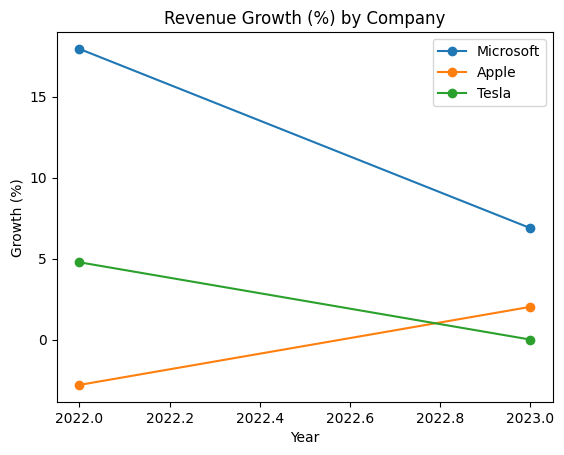

In [12]:
import matplotlib.pyplot as plt

# Revenue Growth's graph
for company in df['Company'].unique():
    subset = df[df['Company'] == company]
    plt.plot(subset['Year'], subset['Revenue Growth (%)'], marker='o', label=company)

plt.title("Revenue Growth (%) by Company")
plt.xlabel("Year")
plt.ylabel("Growth (%)")
plt.legend()
plt.show()


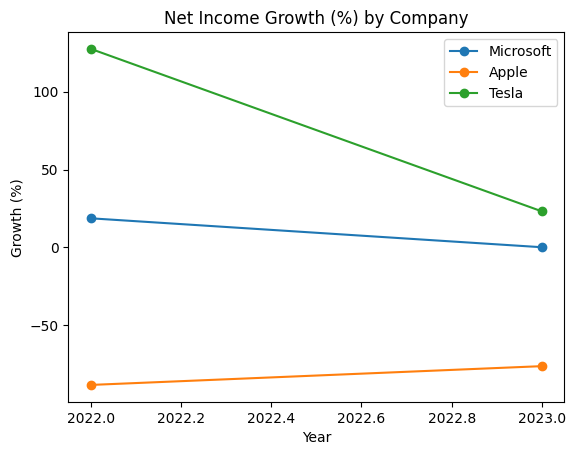

In [13]:
# Net Income Growth Graph
for company in df['Company'].unique():
    subset = df[df['Company'] == company]
    plt.plot(subset['Year'], subset['Net Income Growth (%)'], marker='o', label=company)

plt.title("Net Income Growth (%) by Company")
plt.xlabel("Year")
plt.ylabel("Growth (%)")
plt.legend()
plt.show()


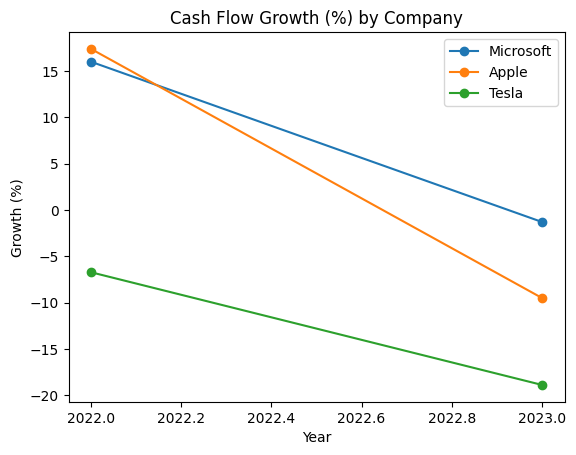

In [16]:
# Cash Flow Growth Graph
for company in df['Company'].unique():
    subset = df[df['Company'] == company]
    plt.plot(subset['Year'], subset['Cash Flow Growth (%)'], marker='o', label=company)

plt.title("Cash Flow Growth (%) by Company")
plt.xlabel("Year")
plt.ylabel("Growth (%)")
plt.legend()
plt.show()


📊 Financial Performance Summary (2021–2023)
🟦 Microsoft

Revenue: Consistent growth from 2021 to 2023.

Net Income: Stable with slight growth, but pace is slower than revenue.

Cash Flow: Strong and steady, showing operational stability.

🟩 Apple

Revenue: Small dip in 2022 but slight recovery in 2023.

Net Income: Sharp decline in 2022, partial recovery in 2023.

Cash Flow: Fluctuating, but overall remains strong.

🟥 Tesla

Revenue: Strong growth till 2022, flattening in 2023.

Net Income: Significant growth across the years (company maturing).

Cash Flow: Volatile but improving over time.

📌 Key Insights

Microsoft shows steady and reliable growth.

Apple faced decline in profitability in 2022 but recovered partially.

Tesla is the fastest-growing in Net Income, but revenue growth is starting to plateau.


In [18]:
print(df.head())
print(df.tail())


     Company  Year  Total Revenue  Net Income  Total Assets  \
0  Microsoft  2021         168.09       61271        333779   
1  Microsoft  2022         198.27       72738        364840   
2  Microsoft  2023         211.92       72842        411942   
3      Apple  2021      394328.00     3365817        352755   
4      Apple  2022      383285.00      394328        352583   

   Total Liabilities  Cash Flow from Ops  Revenue Growth (%)  \
0             205750               76740                 NaN   
1             198298               89035           17.954667   
2             212301               87887            6.884551   
3             153982              104038                 NaN   
4             290437              122151           -2.800461   

   Net Income Growth (%)  Assets Growth (%)  Liabilities Growth (%)  \
0                    NaN                NaN                     NaN   
1              18.715216           9.305858               -3.621871   
2               0.14297